In [67]:
# Imports used throughout the notebook
import numpy as np
from dataclasses import dataclass
from lib.opt_types import *
from lib.utils import *


# Image inpainting with proximal methods

This notebook first implements three methods for minimizing a composite objective, then applies them to recover an image from sampled pixels. The target objective is a data-fit term plus an $\ell_1$ penalty on wavelet coefficients.

The attached copy had missing algorithm registrations, placeholder code cells, no image-loading cell, and a prose explanation inside a code cell. This cleaned copy puts executable code in order and defines the missing names before use.

## Part 1: Composite optimization

For $F(x)=f(x)+g(x)$, $f$ is differentiable and $g$ is nonsmooth. Subgradient descent uses a subgradient of the full objective. ISTA and FISTA use the proximal operator of $g$.


In [68]:
@dataclass
class SubG_state(OptState):
    x_k: Vector
    k: int


In [69]:
def SubG_update(composite_function, state):
    f, g = composite_function
    x_k, k = state
    alpha_k = 0.1 / np.sqrt(k)
    subgrad_k = f.grad(x_k) + g.subgrad(x_k)
    x_next = x_k - alpha_k * subgrad_k
    return SubG_state(x_k=x_next, k=k + 1)

def SubG_initialize(composite_function, x_zero):
    return SubG_state(x_k=x_zero.copy(), k=1)

SubG = OptAlgorithm(name="SubG", init_state=SubG_initialize, state_update=SubG_update)


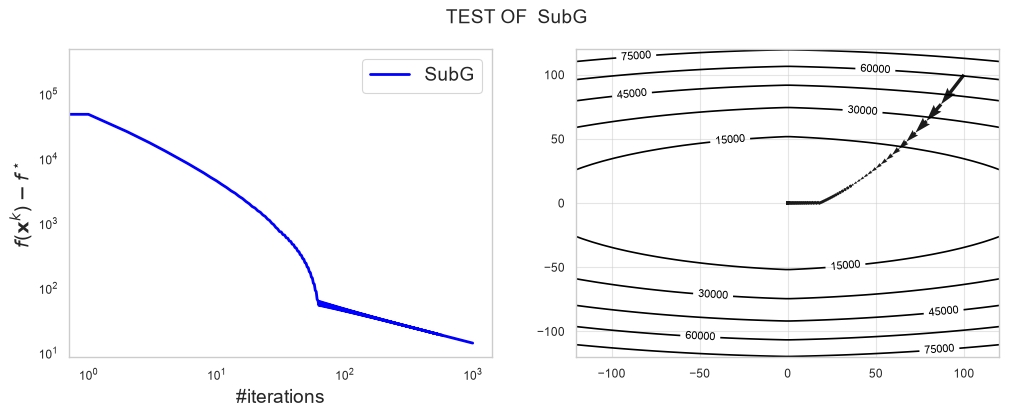

In [70]:
test_composite(SubG)


### Soft thresholding

For $g(z)=\beta\|z\|_1$, the proximal minimization separates by coordinate. Each coordinate is moved toward zero by $\gamma\beta$; values inside that threshold become zero. Thus $\operatorname{prox}_{\gamma g}(z)=\operatorname{sign}(z)\circ\max(|z|-\gamma\beta,0)$.


In [71]:
def l1_prox(gamma, z, beta):
    return np.sign(z) * np.maximum(np.abs(z) - gamma * beta, 0)


### ISTA

ISTA takes a gradient step on $f$ with step size $1/L$, then applies the proximal operator of $g$. The strong convexity parameter is used in the convergence theory; this fixed-step update uses the smoothness constant.


In [72]:
@dataclass
class ISTA_state(OptState):
    x_k: Vector


In [73]:
def ISTA_update(composite_function, state):
    f, g = composite_function
    (x_k,) = state
    alpha = 1.0 / f.lips_grad
    z = x_k - alpha * f.grad(x_k)
    x_next = g.prox(alpha, z)
    return ISTA_state(x_k=x_next)

def ISTA_initialize(composite_function, x_zero):
    return ISTA_state(x_k=x_zero.copy())

ISTA = OptAlgorithm(name="ISTA", init_state=ISTA_initialize, state_update=ISTA_update)


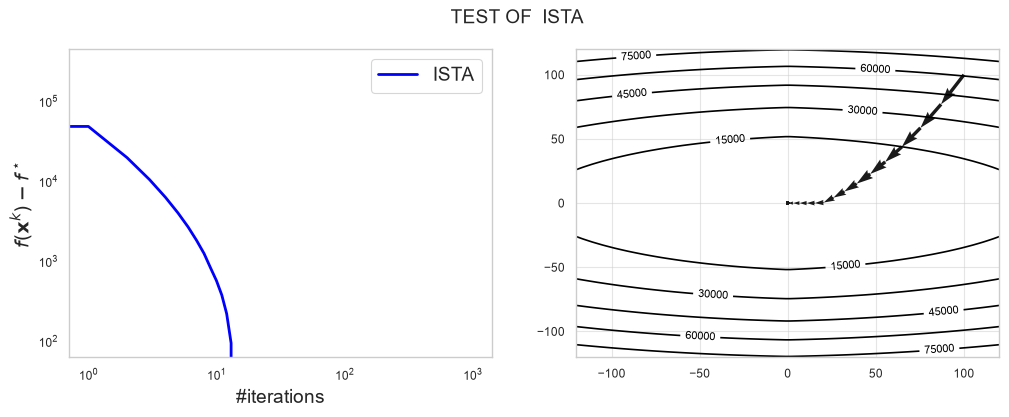

In [74]:
test_composite(ISTA, prox=l1_prox)


### FISTA

FISTA adds a fixed momentum term for strongly convex objectives. Its state includes the current proximal iterate $x_k$, extrapolated point $y_k$, and momentum coefficient $\beta$. The coefficient is determined by $L$ and $\mu$.


In [75]:
@dataclass
class FISTA_state(OptState):
    x_k: Vector
    y_k: Vector
    beta_k: float


In [76]:
def FISTA_update(composite_function, state):
    f, g = composite_function
    x_k, y_k, beta_k = state
    alpha = 1.0 / f.lips_grad
    x_next = g.prox(alpha, y_k - alpha * f.grad(y_k))
    y_next = x_next + beta_k * (x_next - x_k)
    return FISTA_state(x_k=x_next, y_k=y_next, beta_k=beta_k)

def FISTA_initialize(composite_function, x_zero):
    f, _ = composite_function
    beta_k = (np.sqrt(f.lips_grad) - np.sqrt(f.strng_cvx)) / (np.sqrt(f.lips_grad) + np.sqrt(f.strng_cvx))
    x_zero = x_zero.copy()
    return FISTA_state(x_k=x_zero, y_k=x_zero.copy(), beta_k=beta_k)

FISTA = OptAlgorithm(name="FISTA", init_state=FISTA_initialize, state_update=FISTA_update)


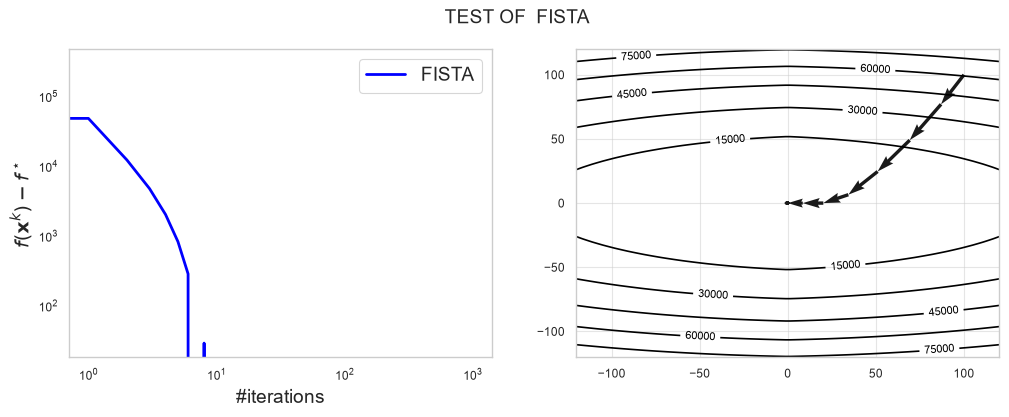

In [77]:
test_composite(FISTA, prox=l1_prox)


### Compare convergence

The expected ordering is FISTA fastest, ISTA next, and SubG slowest. SubG has a sublinear objective-gap guarantee under standard bounded-subgradient assumptions; ISTA and strongly convex FISTA have linear rates, with FISTA's bound improving the dependence on the condition number. The plot is an empirical comparison on the provided quadratic test.


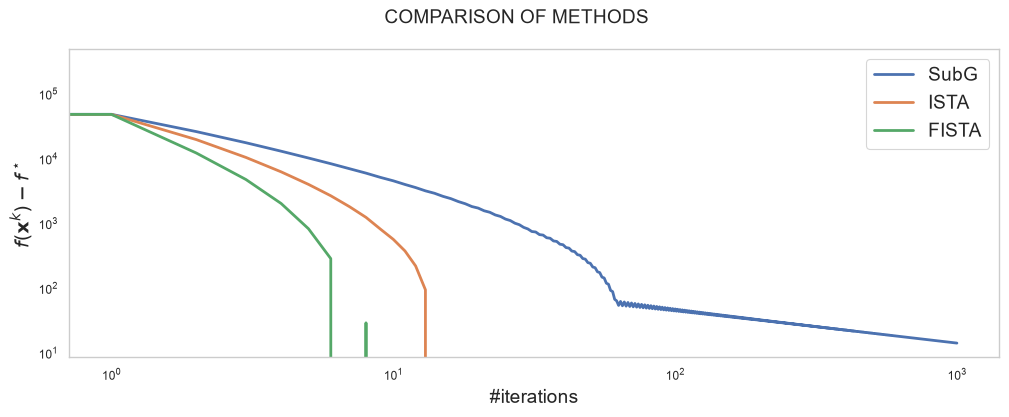

In [78]:
list_of_methods = [SubG, ISTA, FISTA]
compare_composite(list_of_methods, prox=l1_prox)


## Part 2: Image reconstruction

The application uses a grayscale image, samples a subset of its pixels, then solves for wavelet coefficients whose synthesized image fits those observations while remaining sparse in the wavelet basis.


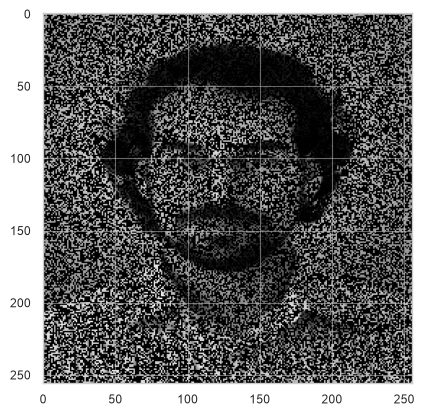

In [79]:
from lib.inpainting import *

image = load("lib/alp.jpg")
subsampled = show_subsampled(image)


In [80]:
x = image.reshape(-1)
b = P(x)


In [81]:
mu = 1e-4
def f_l1(alpha):
    residual = P(W_T(alpha)) - b
    return 0.5 * np.dot(residual, residual) + 0.5 * mu * np.dot(alpha, alpha)


In [82]:
def grad_f_l1(alpha):
    residual = P(W_T(alpha)) - b
    return W(P_T(residual)) + mu * alpha


The Hessian of the data-fit term is $W P^\top P W^\top$. The sampling operator has norm 1 and the wavelet transform is orthonormal, so this term has norm at most 1. The quadratic regularizer adds $\mu I$, giving the Lipschitz constant $L=1+\mu$.


In [88]:
lips_grad_f_l1 = 1.0 + mu


In [84]:
f_l1 = Function(f=f_l1, grad=grad_f_l1, lips_grad=lips_grad_f_l1, strng_cvx=mu)


In [85]:
l1 = Function(
    f=lambda x: np.sum(np.abs(x), axis=0),
    prox=lambda gamma, z: l1_prox(gamma, z, beta=1)
)
g_l1 = Regularizer(l1)


In [86]:
composite_objective = CompositeFunction(f=f_l1, g=g_l1)


In [87]:
lmda = 0.01
out = solve_composite(FISTA, composite_objective, lmda, max_iterations=500)
flat_image_out = W_T(out)
image_out = flat_image_out.reshape(image.shape)
show(true=image, subsampled=subsampled, estimated=image_out)


KeyboardInterrupt: 

### Grid search for the regularization weight

We use a **grid search**: choose a fixed set of candidate values for $\lambda$, solve the reconstruction problem for each value, and compare the resulting images using PSNR. The code tests 30 logarithmically spaced candidates from $10^{-3}$ to $10^1$. Logarithmic spacing explores values across several scales, since the useful regularization weight may differ by multiplicative factors.

For this experiment, the original image is available, so we can compute each candidate reconstruction's PSNR against it. The selected value is the one with the highest PSNR among the 30 candidates; it is not necessarily the exact global optimum. If the best candidate is at either endpoint of the grid, extend the range and search again.

`solve_composite` plots its convergence history on every run. During the search, the code temporarily suppresses those intermediate plots and closes each figure to avoid filling the notebook with 30 plots or triggering Matplotlib's open-figure warning. It then reruns FISTA with the selected value and displays the final reconstruction.


In [ ]:
lambda_candidates = np.logspace(-3, 1, 30)
psnr_results = []

# Suppress the plot made inside solve_composite during the grid search.
original_show = plt.show
try:
    plt.show = lambda *args, **kwargs: None
    for candidate in lambda_candidates:
        alpha_candidate = solve_composite(
            FISTA, composite_objective, float(candidate), max_iterations=500
        )
        image_candidate = W_T(alpha_candidate).reshape(image.shape)
        psnr_results.append(PSNR(image, image_candidate))
        plt.close("all")
finally:
    plt.show = original_show
    plt.close("all")

best_index = int(np.argmax(psnr_results))
best_lmda = float(lambda_candidates[best_index])
best_psnr = float(psnr_results[best_index])
print("Best lambda:", best_lmda, "PSNR:", best_psnr)
if best_index in (0, len(lambda_candidates) - 1):
    print("The best value is at a grid endpoint; consider extending the search range.")

# Refit with the best tested lambda and display the final result.
out_best = solve_composite(
    FISTA, composite_objective, best_lmda, max_iterations=500
)
image_best = W_T(out_best).reshape(image.shape)
show(true=image, subsampled=subsampled, estimated=image_best)
